In [33]:
from datasets import load_dataset
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
import random

## **Carga del dataset**

In [ ]:
DATASET_NAME: int = "microsoft/cats_vs_dogs"

dataset = load_dataset(DATASET_NAME)

## **Exploración general**

In [6]:
dataset["train"].features

{'image': Image(mode=None, decode=True),
 'labels': ClassLabel(names=['cat', 'dog'])}

In [7]:
dataset["train"][0]

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=500x375>,
 'labels': 0}

In [9]:
dataset["train"].features["labels"].names

['cat', 'dog']

## **Distribución de clases**

In [ ]:
labels = dataset["train"]["labels"]
label_names = dataset["train"].features["labels"].names

df_labels = pd.Series(labels).map(lambda x: label_names[x])
labels_count_series = df_labels.value_counts()
cats_prop = round((labels_count_series.iloc[0] * 100) / labels_count_series.sum(), 2)
dogs_prop = round((labels_count_series.iloc[1] * 100) / labels_count_series.sum(), 2)

df_distribution = pd.DataFrame({"Categorías":label_names, 
                               "Cantidad de registros":[labels_count_series.iloc[0], labels_count_series.iloc[1]],
                               "Proporciones de imágenes":[f"{cats_prop}%", f"{dogs_prop}%"]}
                               )

df_distribution


,Categorías,Cantidad de registros,Proporciones de imágenes
0,cat,11741,50.15%
1,dog,11669,49.85%


Como es posible observar, el dataset se encuentra prácticamente balanceado (50.15% de imágenes de gatos y 49.85% de imágenes de perros).

## **Análisis de imágenes**

In [ ]:
sizes = []
corrupted = 0

for example in tqdm(dataset["train"]):
    try:
        img = example["image"]
        sizes.append(img.size)
    except Exception:
        corrupted += 1

print(f"Cantidad de imágenes corruptas: {corrupted}")

100%|██████████| 23410/23410 [00:22<00:00, 1051.03it/s]

Cantidad de imágenes corruptas: 0


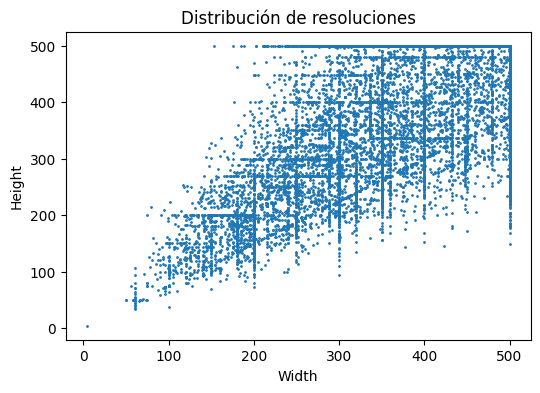

In [ ]:
widths, heights = zip(*sizes)

plt.figure(figsize=(6,4))
plt.scatter(widths, heights, s=1)
plt.xlabel("Width")
plt.ylabel("Height")
plt.title("Distribución de resoluciones")
plt.show()

Si observamos con detenimiento, podremos ver que el tamaño de las imágenes es bastante variado, por lo que será necesario hacer un re escalado.

## **Visualización de las muestras**

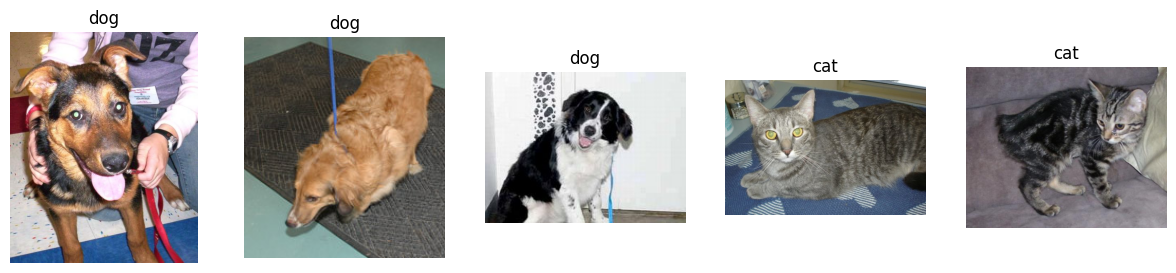

In [35]:
def show_samples(dataset, n=5):
    ig, axes = plt.subplots(1, n, figsize=(15,3))
    for ax in axes:
        idx = random.randint(0, len(dataset)-1)
        sample = dataset[idx]
        ax.imshow(sample["image"])
        ax.set_title(label_names[sample["labels"]])
        ax.axis("off")

show_samples(dataset["train"], 5)

## **Conclusiones**
1. Dataset con clases balanceadas.
2. No se encontraron imágenes corruptas, por lo que no es necesario un filtrado.
3. Variabilidad pronunciada en el tamaño de las imágenes. 